In [1]:
import concurrent.futures
import http.client
import time
import urllib.error

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.table import Table
from astropy.visualization import quantity_support
from astropy.wcs import WCS
from astroquery.ipac.irsa import Irsa

# Suppress logging temporarily to prevent astropy
# from repeatedly printing out warning notices related to alternate WCSs
import logging
logging.getLogger('astropy').setLevel(logging.ERROR)

# The time it takes to read SPHEREx files can exceed
# astropy's default timeout limit. Increase it.
from astropy.utils.data import conf
conf.remote_timeout = 120

# Let matplotlib recognize astropy Quantities and auto-label axes with their units.
quantity_support()

<astropy.visualization.units.quantity_support.<locals>.MplQuantityConverterFormatted at 0x107c40830>

In [2]:
# Choose a position: WISE 0855
coord = SkyCoord(ra=133.78948309791494 * u.degree, dec=-7.24294039128244 * u.degree, frame="icrs")

# Choose a cutout size.
size = 0.1 * u.degree

# Choose the bandpass of interest.
bandpass = 'SPHEREx-D6'

# Choose an output filename root for the output MEF file.
output_filename = f"{size.to_value(u.arcmin):g}'_{bandpass}_cutouts_mef.fits"

In [5]:
# Define a query that will search the appropriate SPHEREx metadata tables
# for spectral images that cover the chosen coordinates and match the
# specified bandpass. Return the cutout data access URL and the time of observation.
# Sort by observation time.
query = f"""
SELECT
    'https://irsa.ipac.caltech.edu/' || a.uri || '?center={coord.ra.deg},{coord.dec.deg}d&size={size.value}' AS uri,
    p.time_bounds_lower
FROM spherex.artifact a
JOIN spherex.plane p ON a.planeid = p.planeid
WHERE 1 = CONTAINS(POINT('ICRS', {coord.ra.deg}, {coord.dec.deg}), p.poly)
        AND p.energy_bandpassname = '{bandpass}'
ORDER BY p.time_bounds_lower
"""

# Execute the query and return as an astropy Table.
t1 = time.time()
results = Irsa.query_tap(query)
print("Time to do TAP query: {:2.2f} seconds.".format(time.time() - t1))
print("Number of images found: {}".format(len(results)))

KeyboardInterrupt: 

In [ ]:
# 下載單筆 Cutout，計算波長並整理 FITS Extensions。
def process_cutout(row, coord, cache):
    '''
    Downloads the cutouts given in a row of the table including all SPHEREx images overlapping with a position.

    Parameters:
    ===========

    row : astropy.table row
        Row of a table that will be changed in place by this function. The table
        is created by the SQL TAP query.
    coord : astropy.coordinates.SkyCoord
        Coordinates (same as used for the TAP query).
    cache : bool
        If set to `True`, the output of cached and the cutout processing will run faster next time.
        Turn this feature off by setting ``cache=False``.
    '''

    with fits.open(row["uri"], cache=cache) as hdulist:
        # There are seven HDUs:
        # 0 contains minimal metadata in the header and no data.
        # 1 through 6 are: IMAGE, FLAGS, VARIANCE, ZODI, EPSF, WCS-WAVE
        header = hdulist[1].header

        # Compute pixel coordinates corresponding to cutout position.
        spatial_wcs = WCS(header)
        x, y = spatial_wcs.world_to_pixel(coord)

        # Compute wavelength at cutout position.
        spectral_wcs = WCS(header, fobj=hdulist, key="W")
        spectral_wcs.sip = None
        wavelength, bandwidth = spectral_wcs.pixel_to_world(x, y)
        row["central_wavelength"] = wavelength.to(u.micrometer).value

        # The FITS primary header carries the processing version (VERSION), which isn't repeated
        # in the extension headers. Keep it so it isn't silently dropped when we build the
        # combined MEF below.
        row["version"] = hdulist[0].header.get("VERSION", "")

        # Collect the HDUs for this cutout and append the row's cutout_index to the EXTNAME.
        hdus = []
        for hdu in hdulist[1:]:  # skip the primary header
            hdu.header["EXTNAME"] = f"{hdu.header['EXTNAME']}{row['cutout_index']}"
            hdus.append(hdu.copy())  # Copy so the data is available after the file is closed
        row["hdus"] = hdus

In [ ]:
def process_cutout_with_error_handling(row, coord, cache):
    last_error = None
    for attempt in range(3):
        try:
            process_cutout(row, coord, cache=cache)
            return None
        except Exception as e:
            row["hdus"] = None
            last_error = f"{type(e).__name__}: {e}"
            if isinstance(e, urllib.error.HTTPError) and e.code not in (408, 429, 500, 502, 503, 504):
                break
            if attempt < 2:
                time.sleep(2 ** attempt)
    return f"Cutout {int(row['cutout_index'])}: {last_error}"

In [ ]:
results_table_parallel = results.to_table()
results_table_parallel["cutout_index"] = range(1, len(results_table_parallel) + 1)
results_table_parallel["central_wavelength"] = np.full(len(results_table_parallel), np.nan)
results_table_parallel["version"] = np.full(len(results_table_parallel), "", dtype="U32")
results_table_parallel["hdus"] = np.full(len(results_table_parallel), None)

t1 = time.time()
with concurrent.futures.ThreadPoolExecutor(max_workers=10) as executor:
    futures = [executor.submit(process_cutout_with_error_handling, row, coord, False)
               for row in results_table_parallel]
    concurrent.futures.wait(futures)
print("Time to create cutouts in parallel mode: {:2.2f} minutes.".format((time.time() - t1) / 60))

# Drop rows that failed to download.
failed_cutouts_parallel = results_table_parallel[results_table_parallel["hdus"] == None]
print("Failed to get the following cutouts:\n", failed_cutouts_parallel["uri"])
results_table_parallel = results_table_parallel[results_table_parallel["hdus"] != None]


In [ ]:
# Create a summary table HDU with renamed columns
cols = fits.ColDefs([
    fits.Column(name="cutout_index", format="J", array=results_table_parallel["cutout_index"], unit=""),
    fits.Column(name="observation_date", format="D", array=results_table_parallel["time_bounds_lower"], unit="d"),
    fits.Column(name="central_wavelength", format="D", array=results_table_parallel["central_wavelength"], unit="um"),
    fits.Column(name="version", format="A32", array=results_table_parallel["version"], unit=""),
    fits.Column(name="access_url", format="A500", array=results_table_parallel["uri"], unit=""),
])
table_hdu = fits.BinTableHDU.from_columns(cols)
table_hdu.header["EXTNAME"] = "CUTOUT_INFO"

In [ ]:
primary_hdu = fits.PrimaryHDU()
hdulist_list = [primary_hdu, table_hdu]
hdulist_list.extend(hdu for fits_hdulist in results_table_parallel["hdus"] for hdu in fits_hdulist)
combined_hdulist = fits.HDUList(hdulist_list)

In [ ]:
# Write the final MEF
combined_hdulist.writeto(output_filename, overwrite=False)

In [6]:
# 讀取 MEF 中的觀測摘要。
summary_table = Table.read(output_filename , hdu=1)

In [7]:
# 讀取前十張 IMAGE 供預覽。
nbr_images = np.nanmin([10, len(summary_table)])
imgs = []
with fits.open(output_filename) as hdul:
    for ii in range(nbr_images):
        extname = "IMAGE{}".format(summary_table["cutout_index"][ii])
        imgs.append(hdul[extname].data)

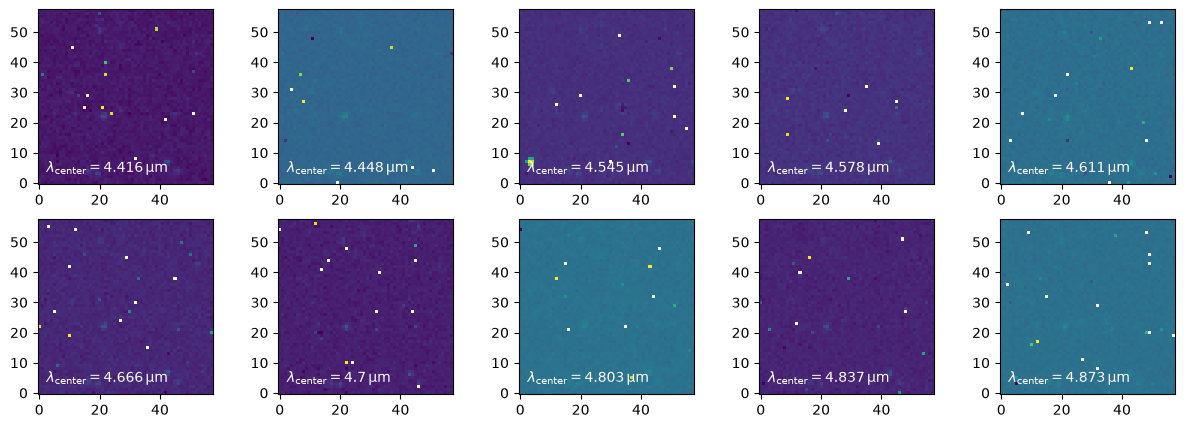

In [8]:
# 繪製前十張 IMAGE 並標示波長。
central_wavelength = summary_table["central_wavelength"].quantity

fig = plt.figure(figsize=(15, 5))
axs = [fig.add_subplot(2, 5, ii + 1) for ii in range(10)]

for ii, img in enumerate(imgs):
    axs[ii].imshow(imgs[ii], norm="log", origin="lower")
    wl = central_wavelength[ii].to(u.micrometer)
    axs[ii].text(0.05, 0.05, rf"$\lambda_{{\rm center}} = {wl.value:2.4g} \,{{\rm \mu m}}$",
                 va="bottom", ha="left", color="white", transform=axs[ii].transAxes)

plt.show()

In [9]:
# 檢查 MEF 的 HDU、資料大小與單位。
from astropy.io import fits

with fits.open(output_filename) as hdul:
    hdul.info()
    for i, hdu in enumerate(hdul):
        print(i, hdu.name, None if hdu.data is None else hdu.data.shape, hdu.header.get("BUNIT"))

Filename: 6'_SPHEREx-D6_cutouts_mef.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  CUTOUT_INFO    1 BinTableHDU     21   25R x 5C   [J, D, D, 32A, 200A]   
  2  IMAGE4        1 ImageHDU       275   (58, 58)   float32   
  3  FLAGS4        1 ImageHDU       185   (58, 58)   int32   
  4  VARIANCE4     1 ImageHDU       119   (58, 58)   float32   
  5  ZODI4         1 ImageHDU       122   (58, 58)   float32   
  6  EPSF4         1 BinTableHDU     56   441R x 11C   [J, J, E, E, E, E, J, E, E, E, 1089D]   
  7  WCS-WAVE4     1 BinTableHDU     22   1R x 3C   [9J, 9J, 162E]   
  8  IMAGE5        1 ImageHDU       275   (58, 58)   float32   
  9  FLAGS5        1 ImageHDU       185   (58, 58)   int32   
 10  VARIANCE5     1 ImageHDU       119   (58, 58)   float32   
 11  ZODI5         1 ImageHDU       122   (58, 58)   float32   
 12  EPSF5         1 BinTableHDU     56   441R x 11C   [J, J, E, E, E, E, J, E, E, E, 1089D]  

In [10]:
# 建立修正後的 Spectral WCS 讀取函式。
from astropy.io import fits
from astropy.wcs import WCS
from astropy.table import Table
import astropy.units as u
import numpy as np

MEF = output_filename
info = Table.read(MEF, hdu="CUTOUT_INFO")

def get_spectral_wcs(hdul, k):
    wave_hdu = hdul[f"WCS-WAVE{k}"].copy()
    wave_hdu.header["EXTNAME"] = "WCS-WAVE"
    wave_hdu.header["EXTVER"] = 1
    temporary_hdul = fits.HDUList([fits.PrimaryHDU(), wave_hdu])
    spectral_wcs = WCS(hdul[f"IMAGE{k}"].header, fobj=temporary_hdul, key="W")
    spectral_wcs.sip = None
    return spectral_wcs

with fits.open(MEF, memmap=True) as hdul:
    k = int(info[0]["cutout_index"])
    spectral_wcs = get_spectral_wcs(hdul, k)
    x, y = 29.0, 29.0
    wavelength, bandwidth = spectral_wcs.pixel_to_world(x, y)
    print(f"IMAGE{k}: wavelength at pixel ({x}, {y}) = {wavelength.to_value(u.um):.6f} um")

IMAGE4: wavelength at pixel (29.0, 29.0) = 4.416104 um


In [11]:
# 統計每張 IMAGE 的觀測時間與波長範圍。

from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
import astropy.units as u
import numpy as np

summary = Table.read(output_filename, hdu="CUTOUT_INFO")
times = np.asarray(summary["observation_date"], dtype=float)

print("Number of images:", len(summary))
print("Number of distinct observation start times:", len(np.unique(times)))
print(f"{'Index':>6} {'Obs. time':>16} {'Target λ (um)':>16} {'Min λ (um)':>14} {'Max λ (um)':>14}")

with fits.open(output_filename, memmap=True) as hdul:
    for row in summary:
        k = int(row["cutout_index"])
        image_hdu = hdul[f"IMAGE{k}"]
        ny, nx = image_hdu.data.shape
        yy, xx = np.indices((ny, nx), dtype=float)

        spectral_wcs = get_spectral_wcs(hdul, k)
        wavelength, bandwidth = spectral_wcs.pixel_to_world(xx, yy)
        wavelength_map = wavelength.to_value(u.um)

        target_wavelength = float(row["central_wavelength"])
        min_wavelength = np.nanmin(wavelength_map)
        max_wavelength = np.nanmax(wavelength_map)

        print(f"{k:6d} {float(row['observation_date']):16.6f} {target_wavelength:16.6f} {min_wavelength:14.6f} {max_wavelength:14.6f}")


Number of images: 25
Number of distinct observation start times: 25
 Index        Obs. time    Target λ (um)     Min λ (um)     Max λ (um)
     4     60989.296807         4.416250       4.408224       4.424261
     5     60989.298548         4.447763       4.439743       4.455767
     8     60989.364776         4.544693       4.536419       4.553159
     9     60989.366268         4.578036       4.569685       4.586583
    10     60989.367761         4.611411       4.602852       4.619716
    12     60989.978484         4.665771       4.656972       4.674605
    13     60993.505109         4.699778       4.690910       4.708513
    16     60993.509586         4.802870       4.794017       4.811865
    17     60993.574250         4.837325       4.828411       4.846211
    18     60993.575742         4.872750       4.863568       4.881884
    19     60993.577234         4.908530       4.899334       4.917632
    20     60993.578727         4.944374       4.935127       4.953493
    24   

In [12]:

# Cell 23：將每張原始 IMAGE 做 WCS 對齊，依觀測時間輸出 GIF，不進行疊合或品質遮罩。

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from scipy.ndimage import map_coordinates
from PIL import Image
from pathlib import Path

MEF_PATH = output_filename
OUTPUT_GIF = f"{size.to_value(u.arcmin):g}'_{bandpass}_individual_images_aligned.gif"
FRAME_DIR = Path("individual_aligned_frames")
FRAME_DIR.mkdir(exist_ok=True)

# 將沒有天空覆蓋範圍的 NaN 顯示為黑色
cmap = plt.get_cmap("gray_r").copy()
cmap.set_bad(color="white")

def align_image_only(data, native_wcs, reference_wcs, output_shape):
    yy, xx = np.indices(output_shape, dtype=float)
    sky = reference_wcs.pixel_to_world(xx, yy)
    sx, sy = native_wcs.world_to_pixel(sky)

    coords = np.array([sy, sx], dtype=float)
    valid_coords = np.isfinite(sx) & np.isfinite(sy)
    coords[:, ~valid_coords] = -100.0

    aligned = map_coordinates(np.asarray(data, dtype=float), coords, order=1, mode="constant", cval=np.nan, prefilter=False)
    aligned[~valid_coords] = np.nan
    return aligned

with fits.open(MEF_PATH, memmap=True) as hdul:
    rows = sorted(hdul["CUTOUT_INFO"].data, key=lambda r: float(r["observation_date"]))

    ref_k = int(rows[0]["cutout_index"])
    ref_hdu = hdul[f"IMAGE{ref_k}"]
    reference_wcs = WCS(ref_hdu.header).celestial
    output_shape = ref_hdu.data.shape

    aligned_images = []

    for row in rows:
        k = int(row["cutout_index"])
        image_hdu = hdul[f"IMAGE{k}"]
        data = np.asarray(image_hdu.data, dtype=float)
        native_wcs = WCS(image_hdu.header).celestial

        if k == ref_k:
            aligned = data.copy()
        else:
            aligned = align_image_only(data, native_wcs, reference_wcs, output_shape)

        mjd = float(image_hdu.header.get("MJD-AVG", row["observation_date"]))
        wavelength = float(row["central_wavelength"])

        original_nan = np.count_nonzero(~np.isfinite(data))
        aligned_nan = np.count_nonzero(~np.isfinite(aligned))

        print(f"IMAGE{k:02d} | MJD={mjd:.6f} | Original NaN={original_nan} | Aligned NaN={aligned_nan}")

        aligned_images.append((k, mjd, wavelength, aligned))

    valid_values = np.concatenate([img[np.isfinite(img)] for _, _, _, img in aligned_images if np.any(np.isfinite(img))])
    vmin, vmax = np.percentile(valid_values, [5, 99.9])

    frame_paths = []

    for i, (k, mjd, wavelength, img) in enumerate(aligned_images, start=1):
        fig = plt.figure(figsize=(8, 8))
        ax = fig.add_subplot(111, projection=reference_wcs)

        ax.imshow(np.ma.masked_invalid(img), origin="lower", cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
        ax.set_xlim(output_shape[1]-0.5, -0.5)
        ax.set_ylim(output_shape[0]-0.5, -0.5)
        ax.set_xlabel("RA")
        ax.set_ylabel("Dec")
        ax.set_title(f"Frame {i}/{len(aligned_images)} | IMAGE{k} | MJD {mjd:.6f}\nReference wavelength: {wavelength:.4f} um")

        path = FRAME_DIR / f"frame_{i:03d}_IMAGE{k:03d}.png"
        fig.savefig(path, dpi=120)
        plt.close(fig)
        frame_paths.append(path)

gif_frames = []
for path in frame_paths:
    with Image.open(path) as im:
        gif_frames.append(im.convert("RGB").copy())

gif_frames[0].save(OUTPUT_GIF, save_all=True, append_images=gif_frames[1:], duration=900, loop=0)

print(f"\nSaved: {OUTPUT_GIF}")
print(f"Total frames: {len(gif_frames)}")

'''
## 這次與之前的差別

| 處理 | 舊版 Cell 23 | 新版 Cell 23 |
|---|---|---|
| WCS 對齊 | 有 | 有 |
| 跨影像疊合 | 無 | 無 |
| FLAGS 遮罩 | 有 | **無** |
| VARIANCE 篩選 | 有 | **無** |
| 背景中位數扣除 | 有 | **無** |
| 嚴格的 0.999 有效權重門檻 | 有 | **移除** |
| GIF 幀數 | 31 | 31 |
| Source / PSF 標記 | 有 | 暫時移除，先檢查原始影像 |
| 超出原始影像覆蓋範圍的像素 | NaN | NaN（顯示黑色） |

這次的 `Original NaN` 和 `Aligned NaN` 輸出特別重要，可以直接比較重新投影前後的缺值數量。如果對齊後某張圖仍有大量 NaN，就能進一步確認是否是 WCS 覆蓋範圍，而不是品質遮罩造成的。

**你現在只需要執行新的 Cell 23，不用重新下載、不用重跑 Cell 18，也不用重新執行 PSF fitting。**

另外，這段程式只做座標重取樣，沒有使用正式的影像光度校正。它適合你現在要的逐幀視覺比較；如果之後要做精確亮度或位置分析，仍然應使用原始 IMAGE 與 ePSF fitting 結果。
'''

IMAGE04 | MJD=60989.297474 | Original NaN=1 | Aligned NaN=1
IMAGE05 | MJD=60989.299215 | Original NaN=3 | Aligned NaN=184
IMAGE08 | MJD=60989.365442 | Original NaN=3 | Aligned NaN=196
IMAGE09 | MJD=60989.366935 | Original NaN=2 | Aligned NaN=123
IMAGE10 | MJD=60989.368427 | Original NaN=2 | Aligned NaN=121
IMAGE12 | MJD=60989.979150 | Original NaN=3 | Aligned NaN=158
IMAGE13 | MJD=60993.505775 | Original NaN=0 | Aligned NaN=115
IMAGE16 | MJD=60993.510252 | Original NaN=0 | Aligned NaN=200
IMAGE17 | MJD=60993.574916 | Original NaN=1 | Aligned NaN=158
IMAGE18 | MJD=60993.576408 | Original NaN=1 | Aligned NaN=169
IMAGE19 | MJD=60993.577901 | Original NaN=0 | Aligned NaN=163
IMAGE20 | MJD=60993.579393 | Original NaN=0 | Aligned NaN=133
IMAGE24 | MJD=61022.029799 | Original NaN=1 | Aligned NaN=121
IMAGE25 | MJD=61151.198599 | Original NaN=1 | Aligned NaN=161
IMAGE32 | MJD=61153.438615 | Original NaN=1 | Aligned NaN=175
IMAGE34 | MJD=61153.441600 | Original NaN=1 | Aligned NaN=148
IMAGE35 | 

'\n## 這次與之前的差別\n\n| 處理 | 舊版 Cell 23 | 新版 Cell 23 |\n|---|---|---|\n| WCS 對齊 | 有 | 有 |\n| 跨影像疊合 | 無 | 無 |\n| FLAGS 遮罩 | 有 | **無** |\n| VARIANCE 篩選 | 有 | **無** |\n| 背景中位數扣除 | 有 | **無** |\n| 嚴格的 0.999 有效權重門檻 | 有 | **移除** |\n| GIF 幀數 | 31 | 31 |\n| Source / PSF 標記 | 有 | 暫時移除，先檢查原始影像 |\n| 超出原始影像覆蓋範圍的像素 | NaN | NaN（顯示黑色） |\n\n這次的 `Original NaN` 和 `Aligned NaN` 輸出特別重要，可以直接比較重新投影前後的缺值數量。如果對齊後某張圖仍有大量 NaN，就能進一步確認是否是 WCS 覆蓋範圍，而不是品質遮罩造成的。\n\n**你現在只需要執行新的 Cell 23，不用重新下載、不用重跑 Cell 18，也不用重新執行 PSF fitting。**\n\n另外，這段程式只做座標重取樣，沒有使用正式的影像光度校正。它適合你現在要的逐幀視覺比較；如果之後要做精確亮度或位置分析，仍然應使用原始 IMAGE 與 ePSF fitting 結果。\n'

NOTE: Full TAP results unavailable; grouping successfully downloaded images only.
Band: SPHEREx-D6 | MEF: 6'_SPHEREx-D6_cutouts_mef.fits
Observations used for grouping: 25
Successfully downloaded: 25
Time-gap threshold: 6.636850 days
Number of groups: 4

=== LARGEST TIME GAPS ===
IMAGE24 -> IMAGE25: 129.16880 days <-- SPLIT
IMAGE20 -> IMAGE24:  28.45041 days <-- SPLIT
IMAGE39 -> IMAGE41:  12.49006 days <-- SPLIT
IMAGE12 -> IMAGE13:   3.52662 days
IMAGE34 -> IMAGE35:   2.64458 days
IMAGE25 -> IMAGE32:   2.24002 days
IMAGE44 -> IMAGE45:   1.16314 days
IMAGE10 -> IMAGE12:   0.61072 days
IMAGE43 -> IMAGE44:   0.40556 days
IMAGE37 -> IMAGE38:   0.33895 days
IMAGE42 -> IMAGE43:   0.33343 days
IMAGE41 -> IMAGE42:   0.20948 days

=== EXACT GROUP MEMBERS ===

Group 01 | MJD 60989.296807–60993.578727 | span=4.282 days
   Images to stack (12): [4, 5, 8, 9, 10, 12, 13, 16, 17, 18, 19, 20]
   Failed downloads (0): []

Group 02 | MJD 61022.029133–61022.029133 | span=0.000 days
   Images to stack (1)

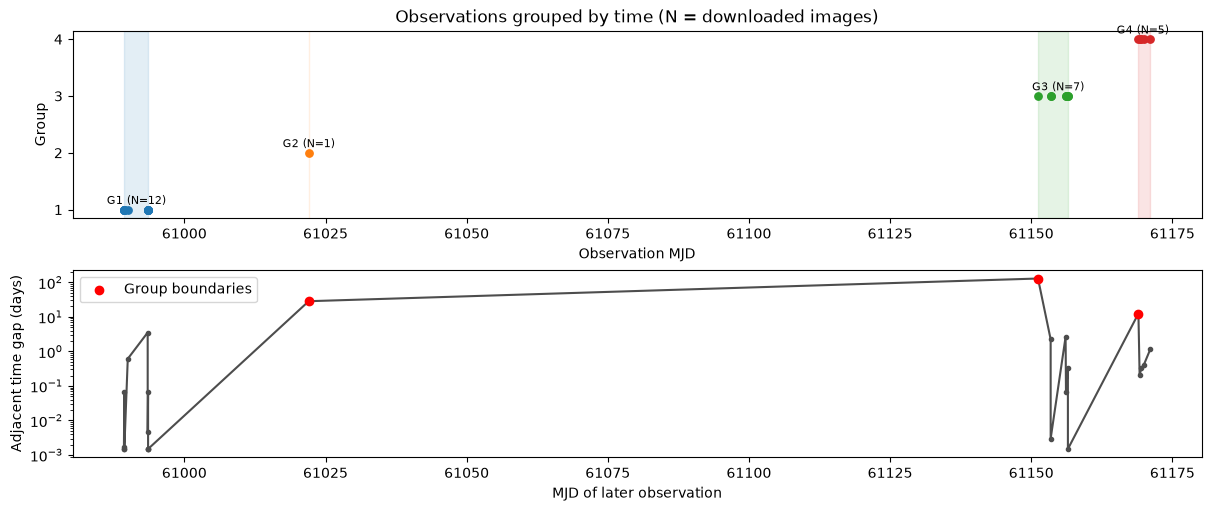

Group 01: stacked 12 images; 100.0% of pixels have >=2 contributions
Group 02: stacked 1 images; 0.0% of pixels have >=2 contributions
Group 03: stacked 7 images; 96.4% of pixels have >=2 contributions


Group 04: stacked 5 images; 95.7% of pixels have >=2 contributions

Saved grouped FITS: 6'_SPHEREx-D6_time_grouped_stacks.fits
Saved inverted GIF: 6'_SPHEREx-D6_time_grouped_aligned.gif | Frames: 4


In [13]:

# Replace the previous last Cell (time grouping + stacking + GIF) with this one.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.table import Table
from PIL import Image

MEF_PATH = Path(output_filename)
NAME_ROOT = MEF_PATH.name.removesuffix('_cutouts_mef.fits')
OUTPUT_FITS = MEF_PATH.with_name(f'{NAME_ROOT}_time_grouped_stacks.fits')
OUTPUT_GIF = MEF_PATH.with_name(f'{NAME_ROOT}_time_grouped_aligned.gif')
FRAME_DIR = MEF_PATH.parent / f'{NAME_ROOT}_time_grouped_frames'
FRAME_DIR.mkdir(parents=True, exist_ok=True)

MIN_GROUPS = 4
MAX_GROUPS = 8
EXTRA_GAP_RATIO = 2.5
BAD_FLAG_BITS = 0
MIN_COVERAGE = 0.90
SUBTRACT_BACKGROUND = True
ROTATE_180 = True
GIF_DURATION_MS = 950

if not MEF_PATH.exists():
    raise FileNotFoundError(f'Cannot find {MEF_PATH.resolve()}')


def choose_time_splits(mjd, min_groups=4, max_groups=8, extra_ratio=2.5):
    """Find the largest gaps in observation time and return split positions."""
    gaps = np.diff(mjd)
    if np.any(gaps < 0):
        raise ValueError('MJD must be sorted')
    possible = np.flatnonzero(gaps > 0)
    if not len(possible):
        return np.array([], dtype=int), np.inf, gaps

    ranked = possible[np.argsort(gaps[possible])[::-1]]
    n_min = min(min_groups - 1, len(ranked))
    n_max = min(max_groups - 1, len(ranked))
    n_cut = n_min

    for k in range(n_min, n_max):
        if gaps[ranked[k - 1]] / gaps[ranked[k]] >= extra_ratio:
            n_cut = k

    cut_gaps = np.sort(ranked[:n_cut])
    threshold = float(np.sqrt(gaps[ranked[n_cut - 1]] * gaps[ranked[n_cut]])) if n_cut < len(ranked) else 0.0
    return cut_gaps, threshold, gaps


def resample_bilinear(image, variance, valid, native_wcs, sky, shape):
    """WCS resampling with propagated input-pixel variances."""
    sx, sy = native_wcs.world_to_pixel(sky)
    finite = np.isfinite(sx) & np.isfinite(sy)
    sx = np.where(finite, sx, -1e8).ravel()
    sy = np.where(finite, sy, -1e8).ravel()
    x0, y0 = np.floor(sx).astype(int), np.floor(sy).astype(int)
    fx, fy = sx - x0, sy - y0

    signal_sum = np.zeros(sx.size, dtype=float)
    weight_sum = np.zeros(sx.size, dtype=float)
    variance_sum = np.zeros(sx.size, dtype=float)
    ny, nx = image.shape

    for dx, dy, w in ((0, 0, (1-fx)*(1-fy)), (1, 0, fx*(1-fy)), (0, 1, (1-fx)*fy), (1, 1, fx*fy)):
        x, y = x0 + dx, y0 + dy
        inside = (x >= 0) & (x < nx) & (y >= 0) & (y < ny) & (w > 0)
        p = np.flatnonzero(inside)
        p = p[valid[y[p], x[p]]]
        if len(p):
            signal_sum[p] += w[p] * image[y[p], x[p]]
            weight_sum[p] += w[p]
            variance_sum[p] += (w[p]**2) * variance[y[p], x[p]]

    ok = weight_sum >= MIN_COVERAGE
    aligned = np.full(sx.size, np.nan)
    aligned_var = np.full(sx.size, np.nan)
    aligned[ok] = signal_sum[ok] / weight_sum[ok]
    aligned_var[ok] = variance_sum[ok] / weight_sum[ok]**2
    return aligned.reshape(shape), aligned_var.reshape(shape)


with fits.open(MEF_PATH, memmap=True) as hdul:
    info = Table(hdul['CUTOUT_INFO'].data)
    downloaded = {int(r['cutout_index']): float(r['observation_date']) for r in info}

    if not downloaded:
        raise ValueError('CUTOUT_INFO has no downloaded images')

    # Include all TAP query results, even failed downloads, when available.
    full_records = None

    if 'results' in globals():
        try:
            query_table = results.to_table()
            full_times = np.asarray(query_table['time_bounds_lower'], dtype=float)
            matching = all(1 <= k <= len(full_times) and np.isclose(full_times[k-1], t, rtol=0, atol=0.001) for k, t in downloaded.items())

            if matching:
                full_records = [{'idx': i+1, 'mjd': float(t), 'available': i+1 in downloaded} for i, t in enumerate(full_times) if np.isfinite(t)]
        except (AttributeError, KeyError, TypeError, ValueError):
            pass

    if full_records is None:
        full_records = [{'idx': k, 'mjd': t, 'available': True} for k, t in downloaded.items()]
        print('NOTE: Full TAP results unavailable; grouping successfully downloaded images only.')

    full_records.sort(key=lambda r: (r['mjd'], r['idx']))
    all_times = np.array([r['mjd'] for r in full_records])
    cut_gaps, threshold, gaps = choose_time_splits(all_times, MIN_GROUPS, MAX_GROUPS, EXTRA_GAP_RATIO)
    groups = np.split(np.array(full_records, dtype=object), cut_gaps + 1)

    print(f'Band: {bandpass} | MEF: {MEF_PATH.name}')
    print(f'Observations used for grouping: {len(full_records)}')
    print(f'Successfully downloaded: {len(downloaded)}')
    print(f'Time-gap threshold: {threshold:.6f} days')
    print(f'Number of groups: {len(groups)}')

    print('\n=== LARGEST TIME GAPS ===')
    for p in np.argsort(gaps)[::-1][:min(12, len(gaps))]:
        flag = ' <-- SPLIT' if p in cut_gaps else ''
        print(f'IMAGE{full_records[p]["idx"]:02d} -> IMAGE{full_records[p+1]["idx"]:02d}: {gaps[p]:9.5f} days{flag}')

    print('\n=== EXACT GROUP MEMBERS ===')

    for j, group in enumerate(groups, 1):
        good_ids = [r['idx'] for r in group if r['available']]
        missing_ids = [r['idx'] for r in group if not r['available']]
        print(f'\nGroup {j:02d} | MJD {group[0]["mjd"]:.6f}–{group[-1]["mjd"]:.6f} | span={group[-1]["mjd"]-group[0]["mjd"]:.3f} days')
        print(f'   Images to stack ({len(good_ids)}): {good_ids}')
        print(f'   Failed downloads ({len(missing_ids)}): {missing_ids}')

    # ============================================================
    # Plot ALL observation times and group boundaries
    # ============================================================

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), constrained_layout=True)
    colors = plt.get_cmap('tab10')

    for j, group in enumerate(groups, 1):
        times_g = [r['mjd'] for r in group]
        ax1.scatter(times_g, np.full(len(times_g), j), color=colors((j-1) % 10), s=28)
        ax1.axvspan(min(times_g), max(times_g), alpha=0.12, color=colors((j-1) % 10))
        ax1.text(np.mean(times_g), j+0.1, f'G{j} (N={sum(r["available"] for r in group)})', ha='center', fontsize=8)

    ax1.set_ylabel('Group')
    ax1.set_xlabel('Observation MJD')
    ax1.set_yticks(range(1, len(groups)+1))
    ax1.set_title('Observations grouped by time (N = downloaded images)')

    ax2.semilogy(all_times[1:], np.maximum(gaps, 1e-9), '.-', color='0.3')
    ax2.scatter(all_times[cut_gaps+1], gaps[cut_gaps], color='red', zorder=5, label='Group boundaries')
    ax2.set_xlabel('MJD of later observation')
    ax2.set_ylabel('Adjacent time gap (days)')
    ax2.legend()

    plt.show()

    # ============================================================
    # Common sky-coordinate reference
    # ============================================================

    ref_idx = min(downloaded, key=downloaded.get)
    ref = hdul[f'IMAGE{ref_idx}']
    ref_wcs = WCS(ref.header).celestial
    shape = ref.data.shape

    yy, xx = np.indices(shape, dtype=float)
    target_sky = ref_wcs.pixel_to_world(xx, yy)

    out_hdus = [fits.PrimaryHDU()]
    stacked = []

    # ============================================================
    # Stack images separately within every time group
    # ============================================================

    for j, group in enumerate(groups, 1):
        members = [r for r in group if r['available']]

        if not members:
            print(f'Group {j:02d}: 0 downloaded images; no stack generated.')
            continue

        numerator = np.zeros(shape, dtype=float)
        denominator = np.zeros(shape, dtype=float)
        n_contrib = np.zeros(shape, dtype=np.uint16)

        for r in members:
            k = r['idx']
            image_hdu = hdul[f'IMAGE{k}']
            image = np.asarray(image_hdu.data, dtype=float)
            variance = np.asarray(hdul[f'VARIANCE{k}'].data, dtype=float)
            valid = np.isfinite(image) & np.isfinite(variance) & (variance > 0)

            if BAD_FLAG_BITS:
                valid &= (np.asarray(hdul[f'FLAGS{k}'].data, dtype=np.int64) & BAD_FLAG_BITS) == 0

            if not valid.any():
                print(f'IMAGE{k}: no valid pixels')
                continue

            if SUBTRACT_BACKGROUND:
                image = image - np.median(image[valid])

            aligned, aligned_var = resample_bilinear(image, variance, valid, WCS(image_hdu.header).celestial, target_sky, shape)
            ok = np.isfinite(aligned) & np.isfinite(aligned_var) & (aligned_var > 0)
            w = 1.0 / aligned_var[ok]

            numerator[ok] += aligned[ok] * w
            denominator[ok] += w
            n_contrib[ok] += 1

        covered = denominator > 0

        if not covered.any():
            print(f'Group {j:02d}: no usable aligned pixels; skipped.')
            continue

        stack = np.full(shape, np.nan)
        stack_var = np.full(shape, np.nan)
        stack[covered] = numerator[covered] / denominator[covered]
        stack_var[covered] = 1.0 / denominator[covered]

        header = ref_wcs.to_header()
        header['BAND'] = str(bandpass)
        header['NINPUT'] = len(members)
        header['MJDSTART'] = float(group[0]['mjd'])
        header['MJDEND'] = float(group[-1]['mjd'])
        header['SRCIDS'] = ','.join(str(r['idx']) for r in members)

        out_hdus.extend([
            fits.ImageHDU(stack.astype(np.float32), header=header, name=f'STACK{j}'),
            fits.ImageHDU(stack_var.astype(np.float32), header=header, name=f'VARIANCE{j}'),
            fits.ImageHDU(n_contrib, header=header, name=f'NCONTRIB{j}')
        ])

        stacked.append((j, group, stack, n_contrib))
        print(f'Group {j:02d}: stacked {len(members)} images; {np.mean(n_contrib >= 2)*100:.1f}% of pixels have >=2 contributions')

    if not stacked:
        raise RuntimeError('No usable group stacks could be generated')

    fits.HDUList(out_hdus).writeto(OUTPUT_FITS, overwrite=True)


# ============================================================
# White background, black-source GIF
# ============================================================

values = np.concatenate([s[2][np.isfinite(s[2])] for s in stacked])
vmin, vmax = np.percentile(values, [3, 99.7])

if vmax <= vmin:
    vmax = vmin + 1

cmap = plt.get_cmap('gray_r').copy()
cmap.set_bad('white')

frames = []

for j, group, stack, n_contrib in stacked:
    fig = plt.figure(figsize=(8, 8), facecolor='white')
    ax = fig.add_subplot(111, projection=ref_wcs)

    ax.imshow(np.ma.masked_invalid(stack), origin='lower', cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')

    if ROTATE_180:
        ax.set_xlim(shape[1]-0.5, -0.5)
        ax.set_ylim(shape[0]-0.5, -0.5)

    ax.set_xlabel('RA')
    ax.set_ylabel('Dec')
    ax.set_title(f'{bandpass} | Group {j}/{len(groups)} | N={sum(r["available"] for r in group)}\nMJD {group[0]["mjd"]:.3f}–{group[-1]["mjd"]:.3f}')

    frame_path = FRAME_DIR / f'group_{j:02d}.png'
    fig.savefig(frame_path, dpi=120, facecolor='white')
    plt.close(fig)

    with Image.open(frame_path) as im:
        frames.append(im.convert('RGB').copy())

frames[0].save(OUTPUT_GIF, save_all=True, append_images=frames[1:], duration=GIF_DURATION_MS, loop=0)

print(f'\nSaved grouped FITS: {OUTPUT_FITS}')
print(f'Saved inverted GIF: {OUTPUT_GIF} | Frames: {len(frames)}')
